In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

pd.set_option("display.max_columns", None)
df = pd.read_csv("../data/raw/orders.csv")
df.head()
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     18 non-null     int64  
 1   order_date   18 non-null     str    
 2   customer_id  18 non-null     str    
 3   product      18 non-null     str    
 4   category     18 non-null     str    
 5   quantity     18 non-null     int64  
 6   unit_price   18 non-null     float64
 7   unit_cost    18 non-null     float64
 8   region       18 non-null     str    
dtypes: float64(2), int64(2), str(5)
memory usage: 1.4 KB


In [ ]:
# Basic quality checks
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate orders:")
print(df["order_id"].duplicated().sum())
df.describe()

Missing values:
order_id       0
order_date     0
customer_id    0
product        0
category       0
quantity       0
unit_price     0
unit_cost      0
region         0
dtype: int64

Duplicate orders:
0


,order_id,quantity,unit_price,unit_cost
count,18.000000,18.000000,18.000000,18.000000
mean,1009.500000,2.166667,62.582222,37.055556
std,5.338539,1.098127,55.833223,38.948642
min,1001.000000,1.000000,18.500000,9.000000
25%,1005.250000,1.250000,31.242500,15.500000
50%,1009.500000,2.000000,42.000000,22.000000
75%,1013.750000,2.750000,62.500000,33.250000
max,1018.000000,5.000000,180.000000,120.000000


In [ ]:
# Data transformation
df["order_date"] = pd.to_datetime(df["order_date"])
df["revenue"] = df["quantity"] * df["unit_price"]
df["cost"] = df["quantity"] * df["unit_cost"]
df["profit"] = df["revenue"] - df["cost"]
df["profit_margin"] = (
    df["profit"] / df["revenue"] * 100
).round(2)
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)
df.head()

,order_id,order_date,customer_id,product,category,quantity,unit_price,unit_cost,region,revenue,cost,profit,profit_margin,order_month
0,1001,2026-01-03,C001,Laptop Stand,Accessories,2,35.00,20.0,London,70.00,40.0,30.00,42.86,2026-01
1,1002,2026-01-04,C002,Wireless Mouse,Accessories,3,18.50,9.0,South East,55.50,27.0,28.50,51.35,2026-01
2,1003,2026-01-05,C003,Keyboard,Accessories,1,42.00,22.0,London,42.00,22.0,20.00,47.62,2026-01
3,1004,2026-01-08,C004,Monitor,Electronics,2,180.00,120.0,Midlands,360.00,240.0,120.00,33.33,2026-01
4,1005,2026-01-11,C005,USB-C Hub,Accessories,4,29.99,14.0,North West,119.96,56.0,63.96,53.32,2026-01


In [ ]:
# Business KPIs
total_revenue = df["revenue"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
average_order_value = df["revenue"].mean()

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Profit: £{total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Total Revenue: £2,086.94
Total Profit: £871.94
Total Orders: 18
Average Order Value: £115.94


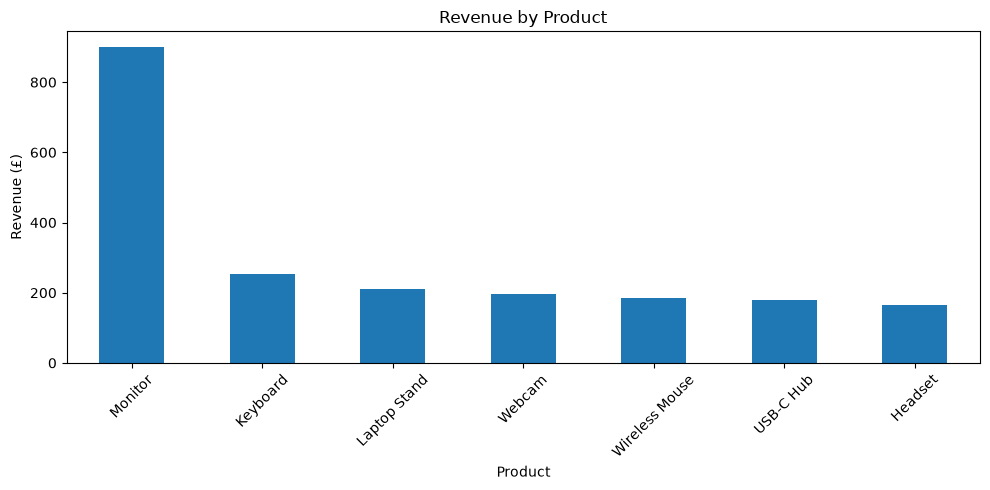

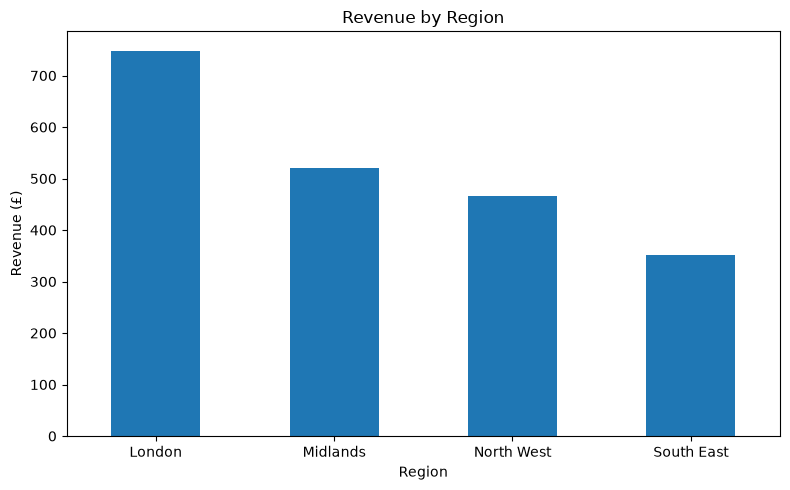

In [ ]:
# Revenue by product
product_revenue = (
    df.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

product_revenue.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Revenue by region
region_revenue = (
    df.groupby("region")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

region_revenue.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

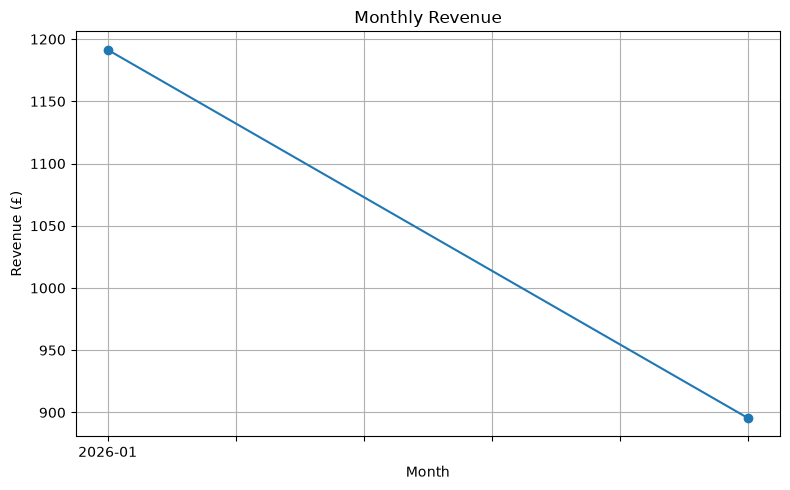

In [16]:
# Monthly revenue
monthly_revenue = (
    df.groupby("order_month")["revenue"]
    .sum()
)

monthly_revenue.plot(
    kind="line",
    marker="o",
    figsize=(8, 5)
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
# SQL analysis
engine = create_engine(
    "sqlite:///../data/warehouse/sales.db"
)
query = """
SELECT
    product,
    SUM(quantity) AS units_sold,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit
FROM sales
GROUP BY product
ORDER BY revenue DESC;
"""

product_analysis = pd.read_sql(query, engine)

product_analysis

query = """
SELECT
    region,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit
FROM sales
GROUP BY region
ORDER BY revenue DESC;
"""

regional_analysis = pd.read_sql(query, engine)

regional_analysis

query = """
SELECT
    order_month,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit
FROM sales
GROUP BY order_month
ORDER BY order_month;
"""

monthly_analysis = pd.read_sql(query, engine)

monthly_analysis

,order_month,revenue,profit
0,2026-01,1191.46,491.46
1,2026-02,895.48,380.48


### Key Findings

- Monitor generated the highest revenue among the products analysed.
- London generated the highest overall revenue of the regions analysed.
- January generated higher revenue and profit than February in the sample.
- Revenue and profit were calculated at transaction level and aggregated using SQL.
- The project demonstrates an end-to-end workflow from raw CSV data through Python transformation and validation to a SQL-based reporting layer.